## 1. Import library dan pengaturan

In [1]:
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_RAW = ROOT / "dataset_raw"
PRAPROSES = ROOT / "data" / "praproses"
MASK = ROOT / "data" / "mask"
LABEL = ROOT / "data" / "labels"
HASIL = ROOT / "hasil" / "anotasi"

KELAS = ["logam", "paper", "plastic"]
WARNA = {"logam": (0, 165, 255), "paper": (0, 200, 0), "plastic": (255, 120, 0)}   # BGR
UKURAN = 640
CONTOH_PER_KELAS = 3     # jumlah contoh acak per kelas yang ditampilkan
LIHAT = []               # isi nama foto untuk memeriksa foto tertentu, mis. ["logam_003.jpg"]. Kosong = contoh acak
SIMPAN_SEMUA = True      # simpan gambar pemeriksaan untuk semua foto

## 2. Usulan kotak dari mask segmentasi

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def kotak_dari_mask(mask):
    """Kotak terkecil yang melingkupi objek pada mask. None jika mask kosong."""
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1


tabel = pd.read_csv(ROOT / "hasil" / "praproses" / "praproses.csv")

usulan = {}      # nama foto -> daftar kotak [(kelas, x1, y1, x2, y2)] dalam piksel 640x640
for r in tabel.itertuples():
    mask = baca(MASK / r.kelas / r.nama_baru.replace(".jpg", ".png"), gray=True)
    kotak = kotak_dari_mask(mask) if mask is not None else None
    usulan[r.nama_baru] = [(r.kelas, *kotak)] if kotak else []

tanpa_usulan = [n for n, k in usulan.items() if not k]
print(f"Usulan kotak dibuat untuk {len(usulan) - len(tanpa_usulan)} dari {len(usulan)} foto.")
print("Foto tanpa usulan (wajib diisi di KOREKSI):", tanpa_usulan if tanpa_usulan else "tidak ada")

Usulan kotak dibuat untuk 394 dari 394 foto.
Foto tanpa usulan (wajib diisi di KOREKSI): tidak ada


## 3. Koreksi manual



In [3]:
KOREKSI = {
}

## 4. Gabungkan usulan dan koreksi, lalu simpan label YOLO

In [4]:
kotak_final = {}
for nama, kotak in usulan.items():
    kotak_final[nama] = KOREKSI.get(nama, kotak)
salah_nama = [n for n in KOREKSI if n not in usulan]
if salah_nama:
    print("Nama foto pada KOREKSI tidak ditemukan:", salah_nama)


def baris_yolo(kelas, x1, y1, x2, y2):
    """Ubah kotak piksel menjadi baris label YOLO (dinormalisasi)."""
    x1, x2 = sorted((min(max(x1, 0), UKURAN), min(max(x2, 0), UKURAN)))
    y1, y2 = sorted((min(max(y1, 0), UKURAN), min(max(y2, 0), UKURAN)))
    if x2 - x1 < 2 or y2 - y1 < 2:
        return None
    return (f"{KELAS.index(kelas)} {(x1 + x2) / 2 / UKURAN:.6f} {(y1 + y2) / 2 / UKURAN:.6f} "
            f"{(x2 - x1) / UKURAN:.6f} {(y2 - y1) / UKURAN:.6f}")


if LABEL.exists():
    shutil.rmtree(LABEL)
LABEL.mkdir(parents=True)

tanpa_label = []
for nama, kotak in kotak_final.items():
    baris = [b for b in (baris_yolo(*k) for k in kotak) if b]
    if baris:
        (LABEL / nama.replace(".jpg", ".txt")).write_text("\n".join(baris) + "\n")
    else:
        tanpa_label.append(nama)

print(f"Label tersimpan: {len(kotak_final) - len(tanpa_label)} file di {LABEL}")
print("Foto tanpa label (tidak ikut dataset):", tanpa_label if tanpa_label else "tidak ada")

Label tersimpan: 394 file di c:\Users\Zubair\Music\WASTIFY_PCV\data\labels
Foto tanpa label (tidak ikut dataset): tidak ada


### Pemeriksaan otomatis koordinat


In [5]:
masalah = []
for f in sorted(LABEL.glob("*.txt")):
    for baris in f.read_text().splitlines():
        kls, cx, cy, w, h = baris.split()
        kls, cx, cy, w, h = int(kls), float(cx), float(cy), float(w), float(h)
        if kls not in (0, 1, 2) or not (0 <= cx - w / 2 and cx + w / 2 <= 1 and 0 <= cy - h / 2 and cy + h / 2 <= 1):
            masalah.append((f.name, "koordinat di luar gambar"))
        elif w * h > 0.9 or w * h < 0.005:
            masalah.append((f.name, f"luas kotak {w * h:.1%} dari gambar, periksa lagi"))

if masalah:
    display(pd.DataFrame(masalah, columns=["label", "catatan"]))
else:
    print("Semua label valid: koordinat berada di dalam gambar dan ukuran kotak wajar.")

Semua label valid: koordinat berada di dalam gambar dan ukuran kotak wajar.


## 5. Periksa hasil anotasi



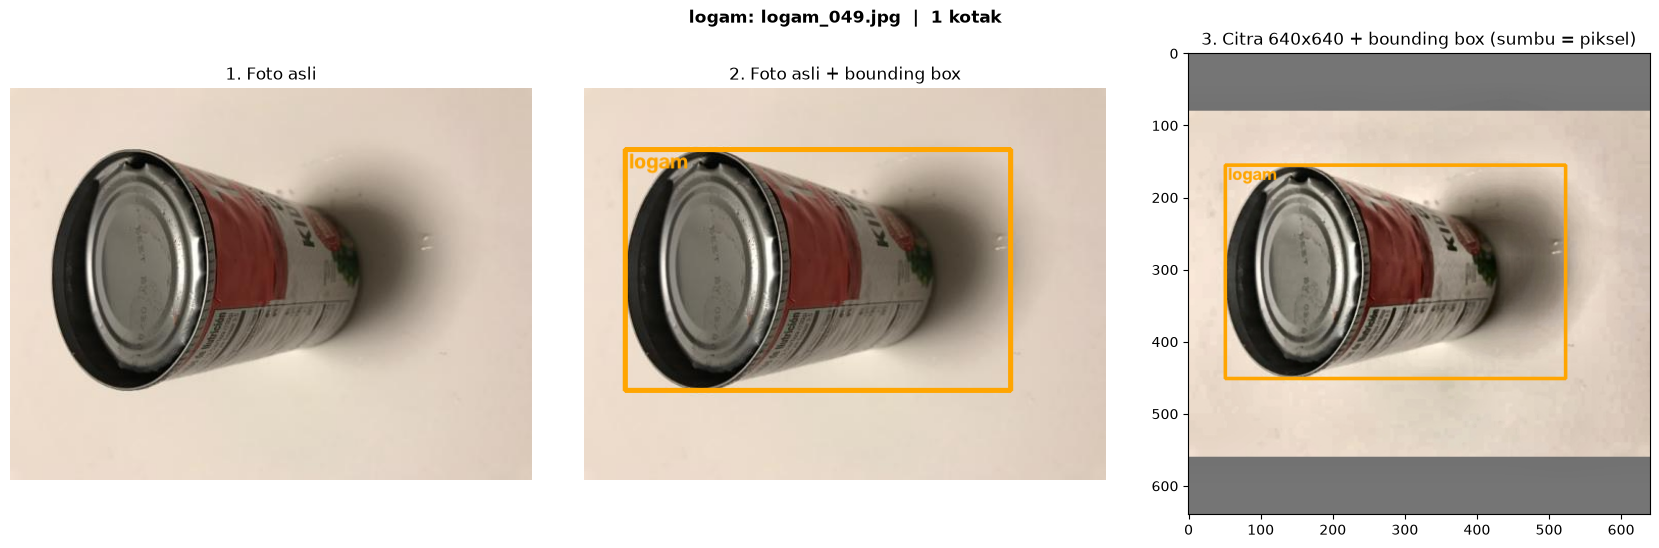

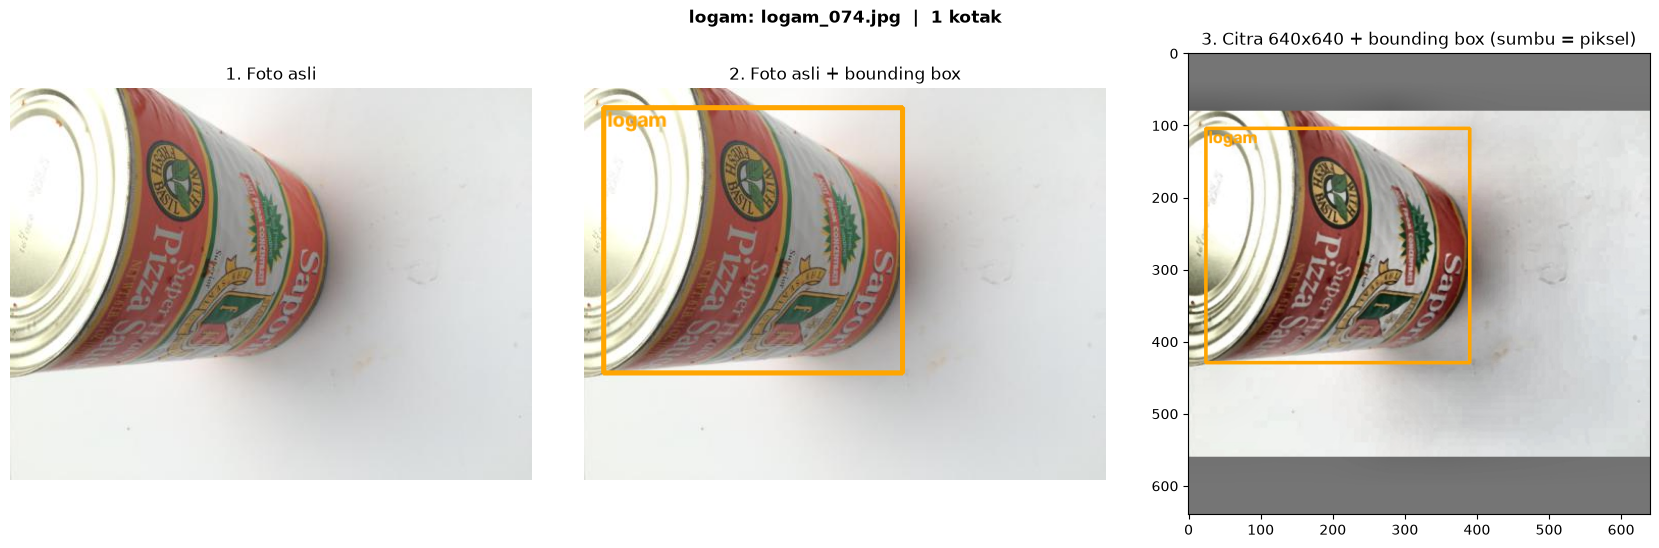

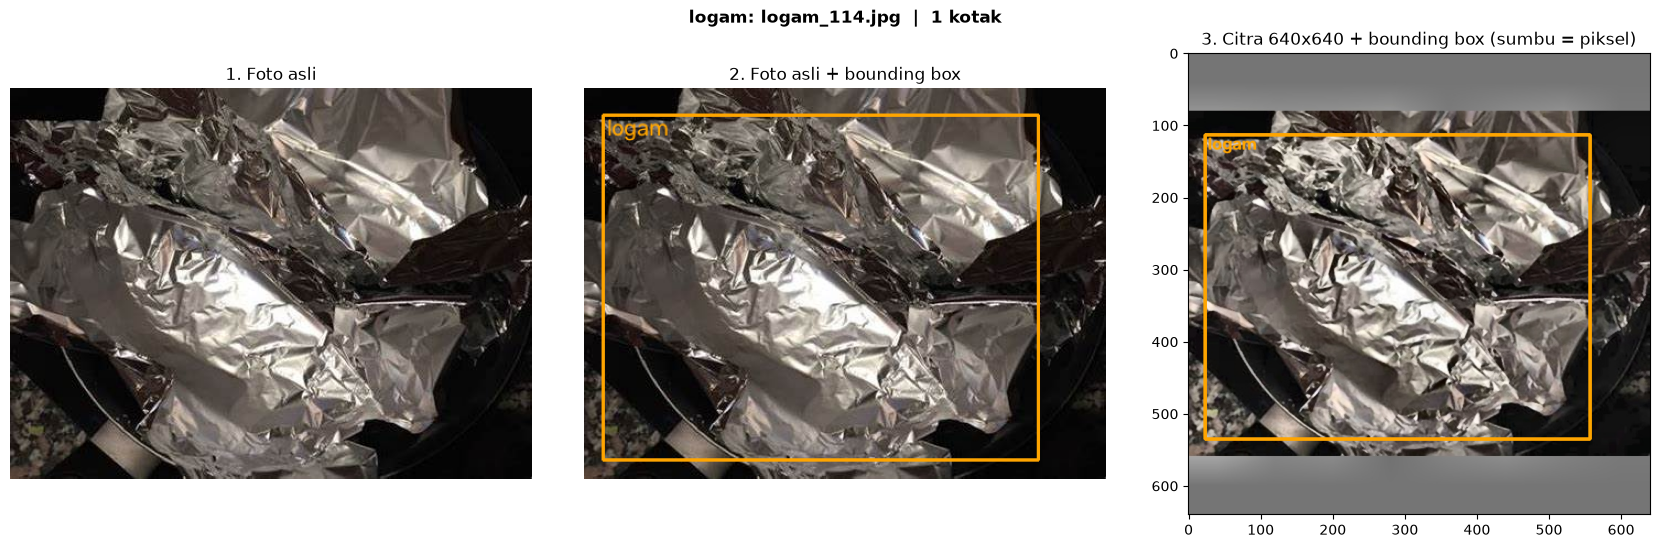

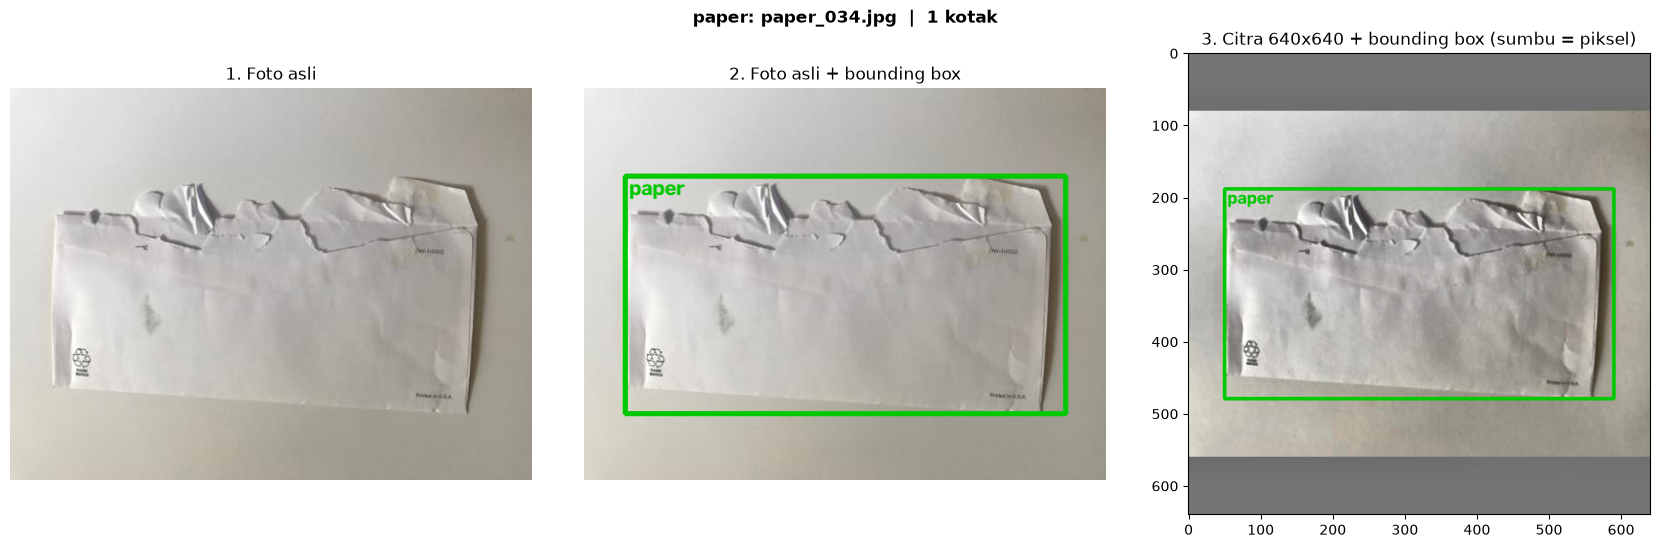

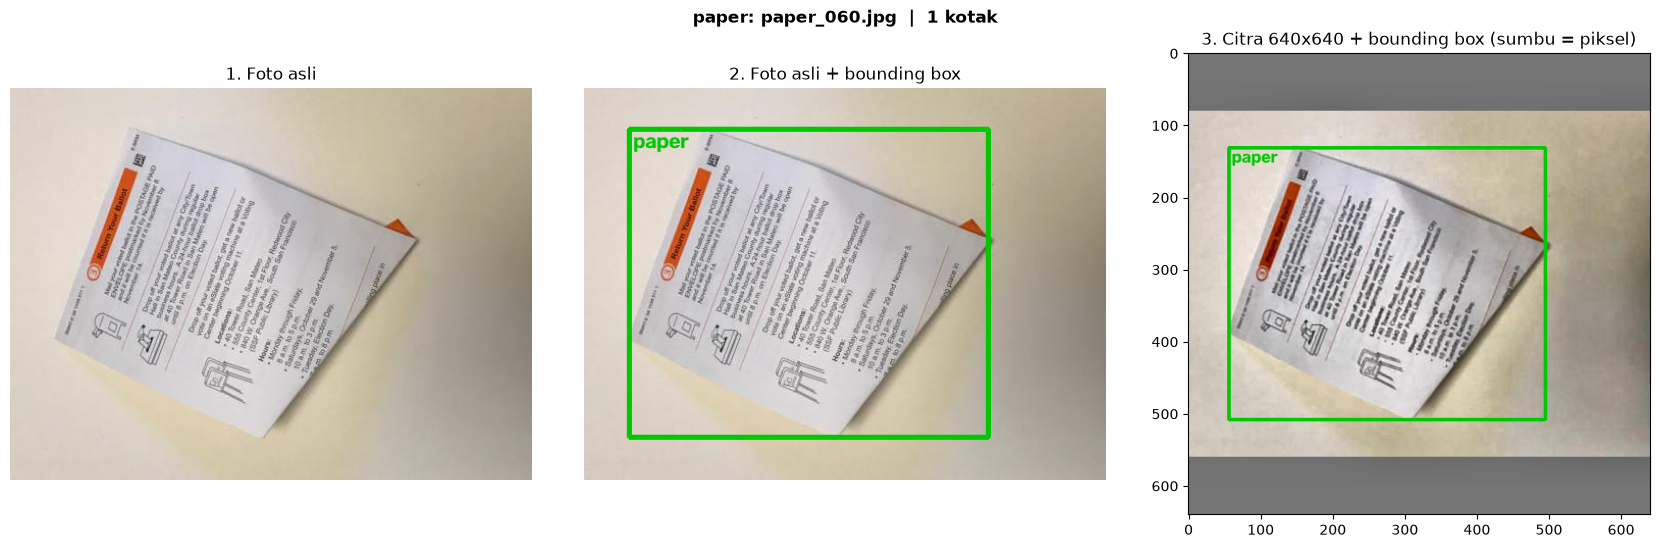

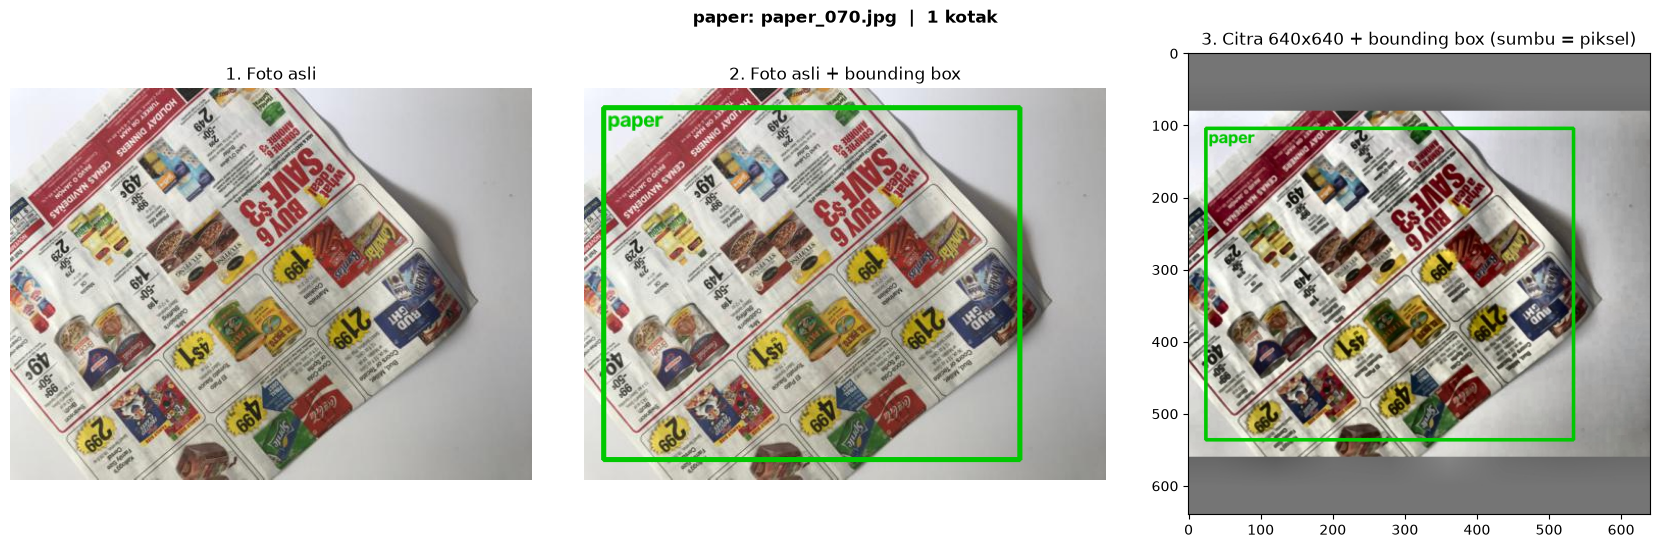

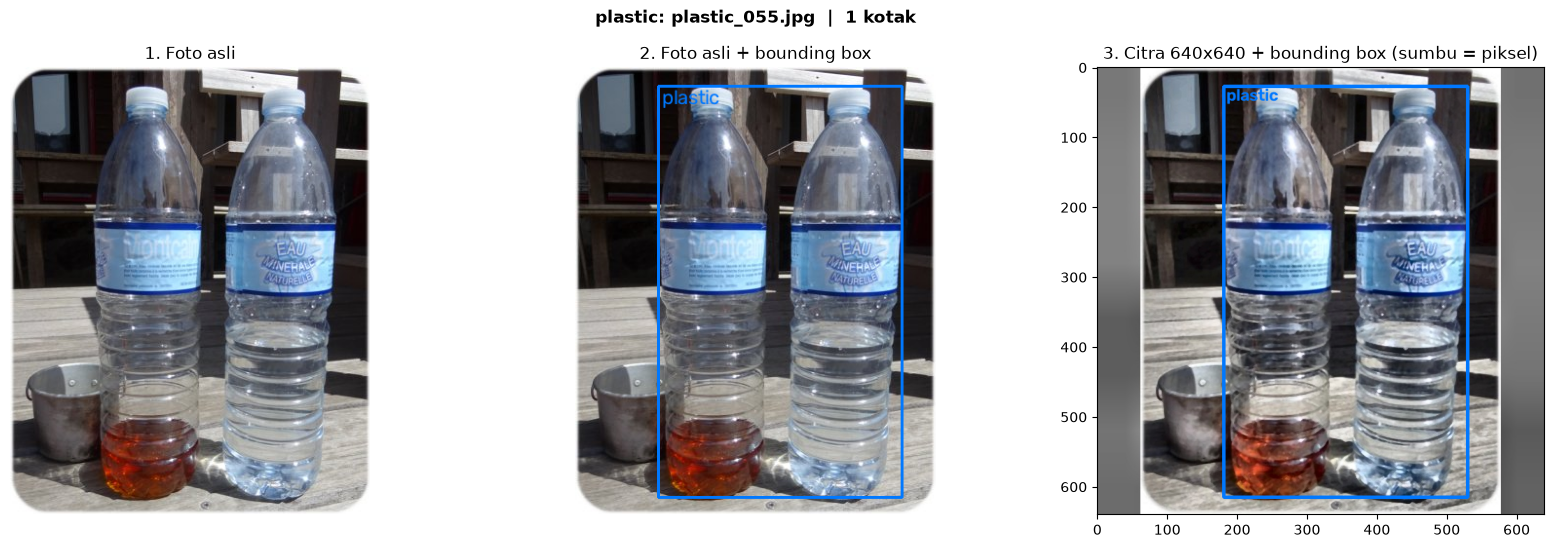

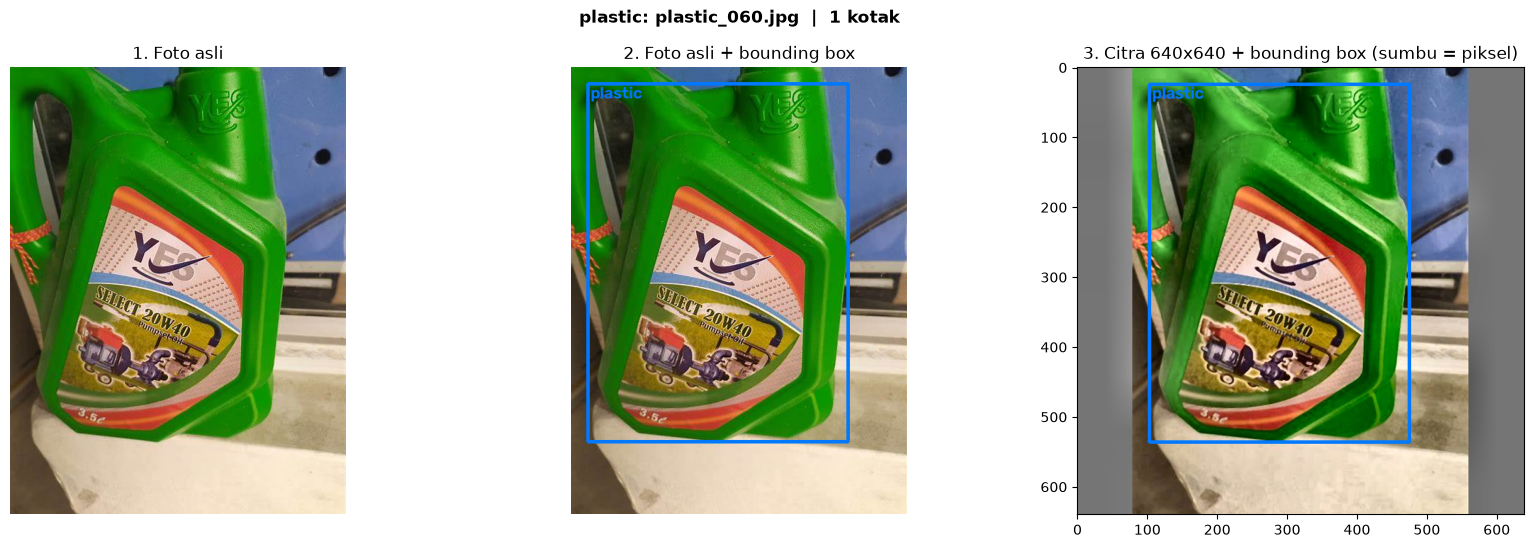

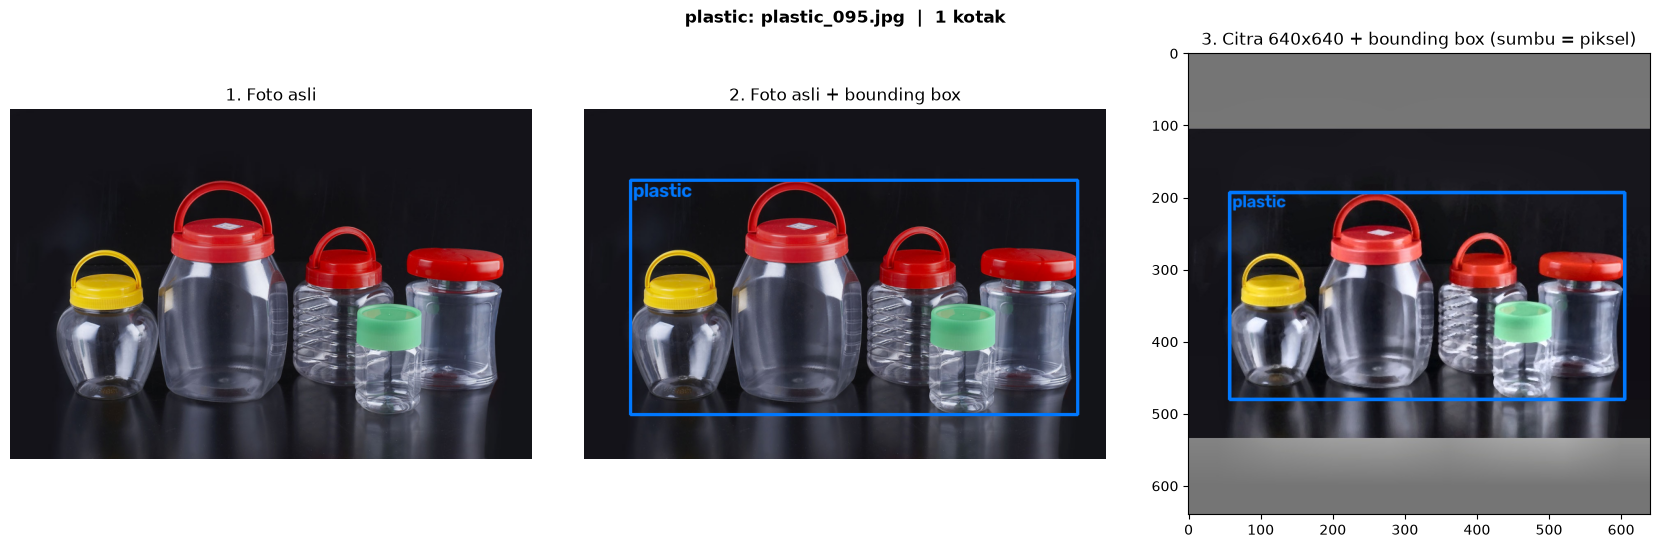

In [6]:
def kecilkan(img, sisi=800):
    h, w = img.shape[:2]
    s = min(1.0, sisi / max(h, w))
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)


def gambar_kotak(img, kotak):
    out = img.copy()
    tebal = max(2, round(min(img.shape[:2]) / 150))
    skala_teks = max(0.7, max(img.shape[:2]) / 800)
    for kelas, x1, y1, x2, y2 in kotak:
        p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(out, p1, p2, WARNA[kelas], tebal)
        cv2.putText(out, kelas, (p1[0] + 4, p1[1] + int(22 * skala_teks) + 4), cv2.FONT_HERSHEY_SIMPLEX,
                    skala_teks, WARNA[kelas], max(1, tebal - 1), cv2.LINE_AA)
    return out


def kotak_ke_asli(kotak, area, lebar, tinggi):
    """Kotak piksel 640x640 -> piksel citra asli (area = kotak foto pada kanvas letterbox)."""
    x1, y1, x2, y2 = area
    sx, sy = lebar / (x2 - x1), tinggi / (y2 - y1)
    return [(k, (a - x1) * sx, (b - y1) * sy, (c - x1) * sx, (d - y1) * sy) for k, a, b, c, d in kotak]


def gambar_anotasi(r, kotak):
    asli = kecilkan(baca(DATASET_RAW / r.kelas / r.nama_asli))
    img = baca(PRAPROSES / r.kelas / r.nama_baru)
    kotak_asli = kotak_ke_asli(kotak, (r.x1, r.y1, r.x2, r.y2), asli.shape[1], asli.shape[0])
    fig, ax = plt.subplots(1, 3, figsize=(17, 5.4))
    ax[0].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB))
    ax[0].set_title("1. Foto asli")
    ax[1].imshow(cv2.cvtColor(gambar_kotak(asli, kotak_asli), cv2.COLOR_BGR2RGB))
    ax[1].set_title("2. Foto asli + bounding box")
    ax[2].imshow(cv2.cvtColor(gambar_kotak(img, kotak), cv2.COLOR_BGR2RGB))
    ax[2].set_title("3. Citra 640x640 + bounding box (sumbu = piksel)")
    ax[2].set_xticks(range(0, UKURAN + 1, 100))
    ax[2].set_yticks(range(0, UKURAN + 1, 100))
    ax[0].axis("off")
    ax[1].axis("off")
    n = len(kotak)
    fig.suptitle(f"{r.kelas}: {r.nama_baru}  |  {n} kotak" + ("" if n else "  |  BELUM ADA KOTAK"),
                 fontsize=12, fontweight="bold")
    fig.tight_layout()
    return fig


if LIHAT:
    tampil = set(LIHAT)
else:
    berlabel = tabel[tabel["nama_baru"].map(lambda n: bool(kotak_final[n]))]
    tampil = set(pd.concat([g.sample(min(CONTOH_PER_KELAS, len(g)), random_state=1)
                            for _, g in berlabel.groupby("kelas")])["nama_baru"])

HASIL.mkdir(parents=True, exist_ok=True)
for r in tabel.itertuples():
    if r.nama_baru not in tampil and not SIMPAN_SEMUA:
        continue
    fig = gambar_anotasi(r, kotak_final[r.nama_baru])
    if SIMPAN_SEMUA:
        fig.savefig(HASIL / r.nama_baru.replace(".jpg", ".png"), dpi=80)
    if r.nama_baru in tampil:
        plt.show()
    plt.close(fig)